# Prediksi Harga Bitcoin: TCN vs RNN vs LSTM

Perbandingan RNN, LSTM, dan TCN untuk memprediksi harga penutupan BTC-USD satu hari ke depan, memakai window 60 hari dan fitur waktu siklis (sin/cos). Metrik evaluasi: RMSE, MAE, dan sMAPE, dirata-ratakan dari 5 seed, lalu dibandingkan dengan baseline naive.

**Tentang output tersimpan:** semua output berasal dari run penuh pada CPU tanggal 6 November 2026 (Python 3.10.11, TensorFlow 2.21.0, Keras 3.12.1). Menjalankan ulang notebook dapat menghasilkan angka yang sedikit berbeda.


## 1. Import


In [1]:
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import tensorflow as tf
import yfinance as yf
from sklearn.manifold import TSNE
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

tf.get_logger().setLevel('ERROR')


## 2. Data dan Fitur

Data harian BTC-USD, ditambah fitur sin/cos untuk siklus tahunan dan bulanan.


In [2]:
print(">>> Mengunduh Data Bitcoin...")
df = yf.download('BTC-USD', start='2014-09-17', end='2025-12-05', auto_adjust=True, progress=False)

# Sinusoidal encoding: mengubah waktu menjadi sinyal siklik untuk pola musiman
df['Date'] = df.index
df['Month'] = df['Date'].dt.month
df['DayOfYear'] = df['Date'].dt.dayofyear

# Pola tahunan
df['year_sin'] = np.sin(2 * np.pi * df['DayOfYear'] / 365.0)
df['year_cos'] = np.cos(2 * np.pi * df['DayOfYear'] / 365.0)
# Pola bulanan
df['month_sin'] = np.sin(2 * np.pi * df['Month'] / 12.0)
df['month_cos'] = np.cos(2 * np.pi * df['Month'] / 12.0)

feature_columns = ['Close', 'year_sin', 'year_cos', 'month_sin', 'month_cos']
data = df[feature_columns].values


>>> Mengunduh Data Bitcoin...


### Normalisasi


In [3]:
# Scaler hanya di-fit pada 80% data awal agar nilai min/max masa depan tidak bocor
train_split_idx = int(len(data) * 0.80)

scaler = MinMaxScaler(feature_range=(0, 1))
scaler.fit(data[:train_split_idx])
scaled_data = scaler.transform(data)


def inverse_close(scaled_close):
    """Mengembalikan kolom Close dari skala 0-1 ke USD."""
    dummy = np.zeros((len(scaled_close), scaled_data.shape[1]))
    dummy[:, 0] = np.ravel(scaled_close)
    return scaler.inverse_transform(dummy)[:, 0]


### Sliding Window dan Split


In [4]:
def create_dataset(dataset, look_back=60):
    """Sliding window: input semua fitur, target hanya Close hari berikutnya."""
    X, Y = [], []
    for i in range(len(dataset) - look_back - 1):
        X.append(dataset[i:(i + look_back), :])
        Y.append(dataset[i + look_back, 0])
    return np.array(X), np.array(Y)


look_back = 60
X, y = create_dataset(scaled_data, look_back)

# Split kronologis 80:20
train_size = int(len(X) * 0.80)
X_train, X_test = X[:train_size], X[train_size:]
y_train, y_test = y[:train_size], y[train_size:]

print(f"Input Shape: {X_train.shape} (Samples, Timesteps, Features)")


Input Shape: (3228, 60, 5) (Samples, Timesteps, Features)


## 3. Arsitektur Model

Ketiga model memiliki bottleneck `latent_layer` Dense(16) yang dipakai untuk analisis t-SNE.


In [5]:
input_shape = (look_back, X_train.shape[2])


def build_tcn(input_shape):
    inputs = tf.keras.Input(shape=input_shape)

    # Proyeksi ke 32 filter agar dimensinya cocok untuk residual connection
    x = tf.keras.layers.Conv1D(filters=32, kernel_size=1, padding='same')(inputs)

    # Dengan kernel 2, receptive field = 64 hari (lebih dari look_back 60)
    for rate in [1, 2, 4, 8, 16, 32]:
        prev_x = x
        conv = tf.keras.layers.Conv1D(filters=32, kernel_size=2, dilation_rate=rate,
                                      padding='causal', activation='relu')(x)
        conv = tf.keras.layers.SpatialDropout1D(0.1)(conv)
        x = tf.keras.layers.Add()([conv, prev_x])

    # Ambil timestep terakhir
    x = tf.keras.layers.Lambda(lambda t: t[:, -1, :])(x)

    # Bottleneck untuk visualisasi t-SNE
    latent_features = tf.keras.layers.Dense(16, activation='relu', name='latent_layer')(x)
    outputs = tf.keras.layers.Dense(1)(latent_features)

    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="TCN")
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')
    return model


def build_lstm(input_shape):
    inputs = tf.keras.Input(shape=input_shape)
    x = tf.keras.layers.LSTM(64, return_sequences=False)(inputs)
    x = tf.keras.layers.Dropout(0.1)(x)
    latent_features = tf.keras.layers.Dense(16, activation='relu', name='latent_layer')(x)
    outputs = tf.keras.layers.Dense(1)(latent_features)
    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="LSTM")
    model.compile(optimizer='adam', loss='mse')
    return model


def build_rnn(input_shape):
    inputs = tf.keras.Input(shape=input_shape)
    x = tf.keras.layers.SimpleRNN(64, return_sequences=False)(inputs)
    x = tf.keras.layers.Dropout(0.1)(x)
    latent_features = tf.keras.layers.Dense(16, activation='relu', name='latent_layer')(x)
    outputs = tf.keras.layers.Dense(1)(latent_features)
    model = tf.keras.Model(inputs=inputs, outputs=outputs, name="RNN")
    model.compile(optimizer='adam', loss='mse')
    return model


## 4. Training dan Evaluasi

Setiap model dilatih dengan 5 seed. Metrik dihitung pada skala USD.


In [6]:
def smape(y_true, y_pred):
    return 100.0 * np.mean(2.0 * np.abs(y_true - y_pred) /
                           (np.abs(y_true) + np.abs(y_pred) + 1e-8))


def reset_seeds(seed_value):
    os.environ['PYTHONHASHSEED'] = str(seed_value)
    random.seed(seed_value)
    np.random.seed(seed_value)
    tf.random.set_seed(seed_value)


seeds = [42, 123, 1234, 2023, 9999]
n_seeds = len(seeds)
epochs = 30
batch_size = 32

models_dict = {
    "RNN": build_rnn,
    "LSTM": build_lstm,
    "TCN": build_tcn,
}

y_test_inv = inverse_close(y_test)


In [7]:
results = []
best_models = {}
best_predictions = {}

print(f"\n>>> TRAINING SEMUA MODEL ({n_seeds} random seeds: {seeds}) <<<\n")

for name, build_fn in models_dict.items():
    print(f"→ {name} ─ {n_seeds} runs")

    rmse_list, mae_list, smape_list, time_list = [], [], [], []
    params = None
    best_rmse = np.inf

    for idx, seed in enumerate(seeds, 1):
        print(f"   Run {idx}/{n_seeds} | seed = {seed:5}", end=" → ")

        reset_seeds(seed)
        model = build_fn(input_shape)

        start = time.time()
        model.fit(X_train, y_train,
                  epochs=epochs, batch_size=batch_size,
                  validation_split=0.1, verbose=0, shuffle=True)
        elapsed = time.time() - start

        pred_scaled = model.predict(X_test, verbose=0).flatten()
        pred_inv = inverse_close(pred_scaled)

        rmse = np.sqrt(mean_squared_error(y_test_inv, pred_inv))
        mae = mean_absolute_error(y_test_inv, pred_inv)
        smape_val = smape(y_test_inv, pred_inv)

        rmse_list.append(rmse)
        mae_list.append(mae)
        smape_list.append(smape_val)
        time_list.append(elapsed)
        if params is None:
            params = model.count_params()

        print(f"RMSE {rmse:.2f} | sMAPE {smape_val:.3f}%")

        if rmse < best_rmse:
            best_rmse = rmse
            best_models[name] = model
            best_predictions[name] = pred_scaled.copy()

    results.append({
        "Model": name,
        "Params": f"{params:,}",
        "Time (s)": f"{np.mean(time_list):.2f} ± {np.std(time_list):.2f}",
        "RMSE": f"{np.mean(rmse_list):.2f} ± {np.std(rmse_list):.2f}",
        "MAE": f"{np.mean(mae_list):.2f} ± {np.std(mae_list):.2f}",
        "sMAPE (%)": f"{np.mean(smape_list):.3f} ± {np.std(smape_list):.3f}",
        "Best RMSE": f"{np.min(rmse_list):.2f}",
        "Best sMAPE": f"{np.min(smape_list):.3f}%",
        # Nilai numerik untuk ranking dan perbandingan baseline
        "RMSE_mean": np.mean(rmse_list),
        "MAE_mean": np.mean(mae_list),
        "sMAPE_mean": np.mean(smape_list),
        "RMSE_best": np.min(rmse_list),
        "sMAPE_best": np.min(smape_list),
    })



>>> TRAINING SEMUA MODEL (5 random seeds: [42, 123, 1234, 2023, 9999]) <<<

→ RNN ─ 5 runs
   Run 1/5 | seed =    42 → RMSE 6506.67 | sMAPE 5.455%
   Run 2/5 | seed =   123 → RMSE 7989.99 | sMAPE 6.711%
   Run 3/5 | seed =  1234 → RMSE 5685.91 | sMAPE 5.263%
   Run 4/5 | seed =  2023 → RMSE 9618.15 | sMAPE 7.676%
   Run 5/5 | seed =  9999 → RMSE 7091.52 | sMAPE 6.229%
→ LSTM ─ 5 runs
   Run 1/5 | seed =    42 → RMSE 5729.15 | sMAPE 5.206%
   Run 2/5 | seed =   123 → RMSE 5232.18 | sMAPE 5.164%
   Run 3/5 | seed =  1234 → RMSE 2572.13 | sMAPE 3.176%
   Run 4/5 | seed =  2023 → RMSE 5955.93 | sMAPE 6.168%
   Run 5/5 | seed =  9999 → RMSE 5053.77 | sMAPE 4.480%
→ TCN ─ 5 runs
   Run 1/5 | seed =    42 → RMSE 3623.41 | sMAPE 3.333%
   Run 2/5 | seed =   123 → RMSE 2334.90 | sMAPE 2.599%
   Run 3/5 | seed =  1234 → RMSE 4076.53 | sMAPE 4.312%
   Run 4/5 | seed =  2023 → RMSE 2731.42 | sMAPE 2.919%
   Run 5/5 | seed =  9999 → RMSE 3137.91 | sMAPE 3.436%


In [8]:
results_df = pd.DataFrame(results)
display_columns = ["Model", "Params", "Time (s)", "RMSE", "MAE", "sMAPE (%)", "Best RMSE", "Best sMAPE"]

print("\n" + "=" * 95)
print(f"HASIL PERBANDINGAN LENGKAP (Rata-rata ± std dari {n_seeds} seed: {', '.join(map(str, seeds))})")
print("=" * 95)
print(results_df[display_columns].to_string(index=False))
print("=" * 95)



HASIL PERBANDINGAN LENGKAP (Rata-rata ± std dari 5 seed: 42, 123, 1234, 2023, 9999)
Model Params     Time (s)              RMSE              MAE     sMAPE (%) Best RMSE Best sMAPE
  RNN  5,537 13.56 ± 0.25 7378.45 ± 1348.87 5482.11 ± 891.13 6.267 ± 0.878   5685.91     5.263%
 LSTM 18,977 33.34 ± 1.26 4908.63 ± 1212.85 3920.78 ± 988.82 4.839 ± 0.990   2572.13     3.176%
  TCN 13,217 23.02 ± 0.62  3180.83 ± 619.28 2450.17 ± 459.59 3.320 ± 0.579   2334.90     2.599%


### Ranking


In [9]:
print("\n" + "═" * 100)
print("RANKING MODEL – HASIL AKHIR".center(100))
print("═" * 100)

print("\n1. RANKING BERDASARKAN RMSE (rata-rata)")
print("─" * 70)
by_rmse = results_df.sort_values("RMSE_mean")
print(by_rmse[["Model", "RMSE", "Best RMSE"]].to_string(index=False))

print("\n2. RANKING BERDASARKAN sMAPE (rata-rata)")
print("─" * 80)
by_smape = results_df.sort_values("sMAPE_mean")
for rank, (_, row) in enumerate(by_smape.iterrows(), 1):
    print(f"{rank}. {row['Model']:<4} │ sMAPE: {row['sMAPE (%)']:>12} │ "
          f"RMSE: {row['RMSE']:>18} │ Best RMSE: {row['Best RMSE']:>8}")
print("═" * 100)

top = by_smape.iloc[0]
print("\nKESIMPULAN (di antara model deep learning):")
print(f"→ Model terbaik        : {top['Model']}")
print(f"→ sMAPE rata-rata      : {top['sMAPE (%)']}")
print(f"→ RMSE rata-rata       : {top['RMSE']}")
print(f"→ Best RMSE (1 run)    : {top['Best RMSE']}")



════════════════════════════════════════════════════════════════════════════════════════════════════
                                    RANKING MODEL – HASIL AKHIR                                     
════════════════════════════════════════════════════════════════════════════════════════════════════

1. RANKING BERDASARKAN RMSE (rata-rata)
──────────────────────────────────────────────────────────────────────
Model              RMSE Best RMSE
  TCN  3180.83 ± 619.28   2334.90
 LSTM 4908.63 ± 1212.85   2572.13
  RNN 7378.45 ± 1348.87   5685.91

2. RANKING BERDASARKAN sMAPE (rata-rata)
────────────────────────────────────────────────────────────────────────────────
1. TCN  │ sMAPE: 3.320 ± 0.579 │ RMSE:   3180.83 ± 619.28 │ Best RMSE:  2334.90
2. LSTM │ sMAPE: 4.839 ± 0.990 │ RMSE:  4908.63 ± 1212.85 │ Best RMSE:  2572.13
3. RNN  │ sMAPE: 6.267 ± 0.878 │ RMSE:  7378.45 ± 1348.87 │ Best RMSE:  5685.91
═════════════════════════════════════════════════════════════════════════════════════

## 5. Perbandingan dengan Baseline Naive

Baseline *persistence* menebak harga besok sama dengan harga hari ini, tanpa training. Model baru bernilai tambah jika error-nya lebih rendah dari baseline ini.


In [10]:
# Prediksi = Close hari sebelumnya, yaitu kolom Close pada timestep terakhir window
baseline_pred = inverse_close(X_test[:, -1, 0])
baseline_rmse = np.sqrt(mean_squared_error(y_test_inv, baseline_pred))
baseline_mae = mean_absolute_error(y_test_inv, baseline_pred)
baseline_smape = smape(y_test_inv, baseline_pred)

comparison = pd.DataFrame(
    [{"Model": "Baseline naive", "RMSE": baseline_rmse, "MAE": baseline_mae,
      "sMAPE (%)": baseline_smape, "Best RMSE": np.nan}]
    + [{"Model": row["Model"], "RMSE": row["RMSE_mean"], "MAE": row["MAE_mean"],
        "sMAPE (%)": row["sMAPE_mean"], "Best RMSE": row["RMSE_best"]}
       for _, row in results_df.iterrows()]
)
comparison["RMSE vs baseline"] = (comparison["RMSE"] / baseline_rmse - 1).map(lambda v: f"{v:+.1%}")

print(f"Baseline dihitung pada {len(y_test_inv)} target test yang sama dengan model.\n")
print(comparison.round({"RMSE": 2, "MAE": 2, "sMAPE (%)": 3, "Best RMSE": 2}).to_string(index=False, na_rep="-"))

print()
for _, row in results_df.iterrows():
    mean_status = "mengalahkan" if row["RMSE_mean"] < baseline_rmse else "kalah dari"
    best_status = "mengalahkan" if row["RMSE_best"] < baseline_rmse else "kalah dari"
    print(f"{row['Model']:<4}: rata-rata RMSE {mean_status} baseline; run terbaik {best_status} baseline.")


Baseline dihitung pada 808 target test yang sama dengan model.

         Model    RMSE     MAE  sMAPE (%)  Best RMSE RMSE vs baseline
Baseline naive 1913.46 1347.06      1.785          -            +0.0%
           RNN 7378.45 5482.11      6.267    5685.91          +285.6%
          LSTM 4908.63 3920.78      4.839    2572.13          +156.5%
           TCN 3180.83 2450.17      3.320    2334.90           +66.2%

RNN : rata-rata RMSE kalah dari baseline; run terbaik kalah dari baseline.
LSTM: rata-rata RMSE kalah dari baseline; run terbaik kalah dari baseline.
TCN : rata-rata RMSE kalah dari baseline; run terbaik kalah dari baseline.


## 6. Visualisasi Prediksi

Setiap panel menampilkan run dengan RMSE test terendah.



>>> Membuat Plot Prediksi...


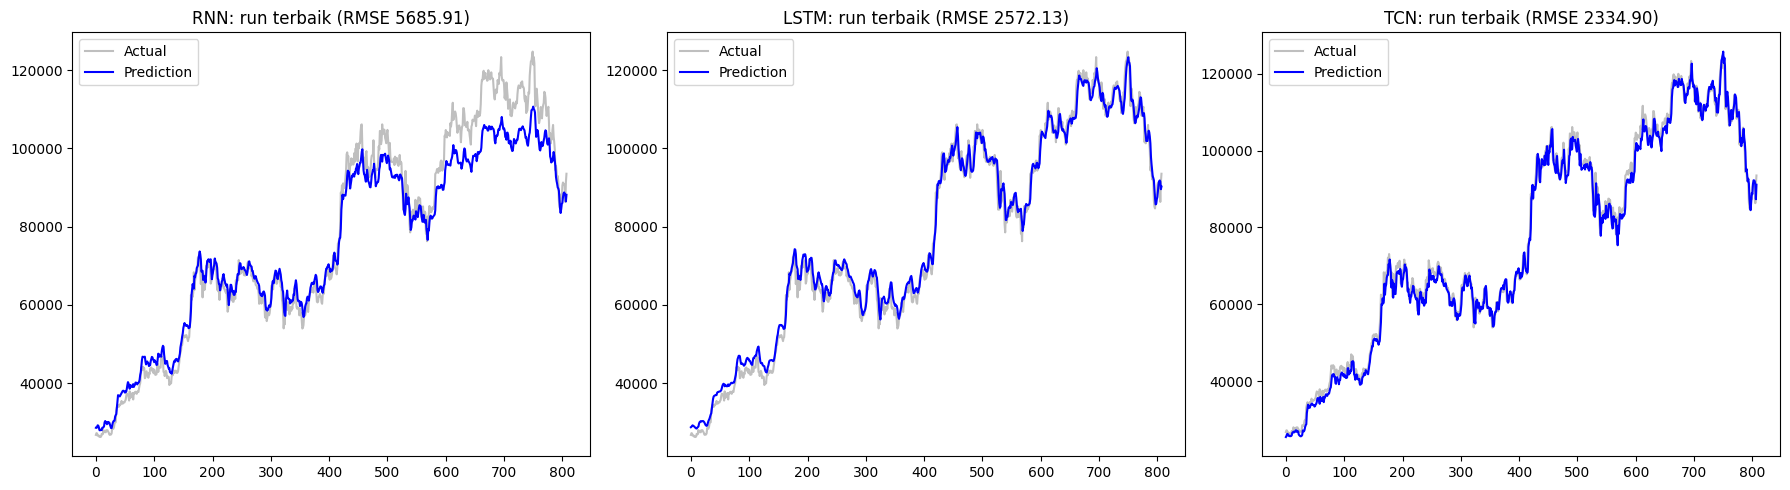

In [11]:
print("\n>>> Membuat Plot Prediksi...")
fig, axes = plt.subplots(1, len(best_predictions), figsize=(18, 5))

for ax, (name, pred) in zip(axes, best_predictions.items()):
    best_rmse = results_df.loc[results_df['Model'] == name, 'Best RMSE'].iloc[0]
    ax.plot(y_test_inv, label='Actual', color='gray', alpha=0.5)
    ax.plot(inverse_close(pred), label='Prediction', color='blue', linewidth=1.5)
    ax.set_title(f"{name}: run terbaik (RMSE {best_rmse})")
    ax.legend()

plt.tight_layout()
plt.show()


## 7. Analisis SHAP (TCN)

Hanya memakai 3 sampel test, jadi hasilnya bersifat indikatif.


In [12]:
model_name = 'TCN'
model_to_explain = best_models[model_name]
print(f">>> Menganalisis Model: {model_name}")

# KernelExplainer mahal, jadi hanya memakai 20 background dan 3 sampel test
background_idx = np.random.choice(X_train.shape[0], 20, replace=False)
test_idx = np.random.choice(X_test.shape[0], 3, replace=False)
X_test_sample_3d = X_test[test_idx]

# Flatten 3D -> 2D karena KernelExplainer menerima input tabular
n_steps, n_features = X_train.shape[1], X_train.shape[2]
total_features = n_steps * n_features
background_data_2d = X_train[background_idx].reshape(len(background_idx), -1)
X_test_sample_2d = X_test_sample_3d.reshape(len(test_idx), -1)


def model_predict_wrapper(data_2d):
    data_3d = data_2d.reshape(-1, n_steps, n_features)
    return model_to_explain.predict(data_3d, verbose=0).flatten()


print(f"Total Fitur: {total_features}. Menggunakan nsamples=600 (Wajib > Total Fitur)...")
print("Proses ini akan memakan waktu sekitar 1-2 menit...")

explainer = shap.KernelExplainer(model_predict_wrapper, background_data_2d)
shap_values_2d = explainer.shap_values(X_test_sample_2d, nsamples=600, l1_reg="num_features(10)")
if isinstance(shap_values_2d, list):
    shap_values_2d = shap_values_2d[0]

# Kembali ke (Samples, Timesteps, Features), lalu jumlahkan dampak per fitur
shap_values_3d = shap_values_2d.reshape(-1, n_steps, n_features)
shap_values_aggr = np.sum(shap_values_3d, axis=1)
X_test_aggr = np.mean(X_test_sample_3d, axis=1)

feature_names = ['Close Price', 'Year_Sin', 'Year_Cos', 'Month_Sin', 'Month_Cos']
print("Kalkulasi selesai.")


>>> Menganalisis Model: TCN
Total Fitur: 300. Menggunakan nsamples=600 (Wajib > Total Fitur)...
Proses ini akan memakan waktu sekitar 1-2 menit...
Kalkulasi selesai.


Faktor Skala Harga: 67388.72512817383 USD


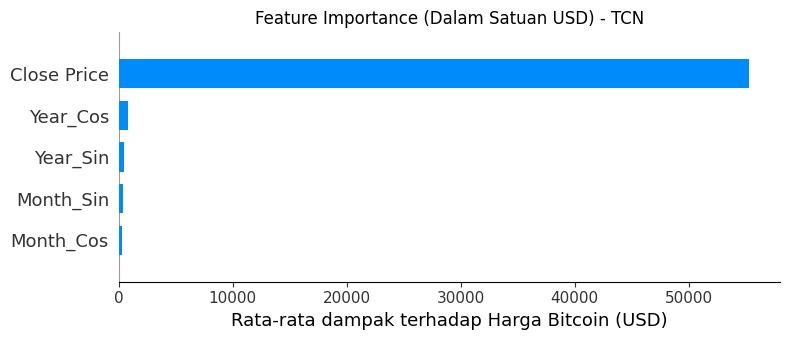

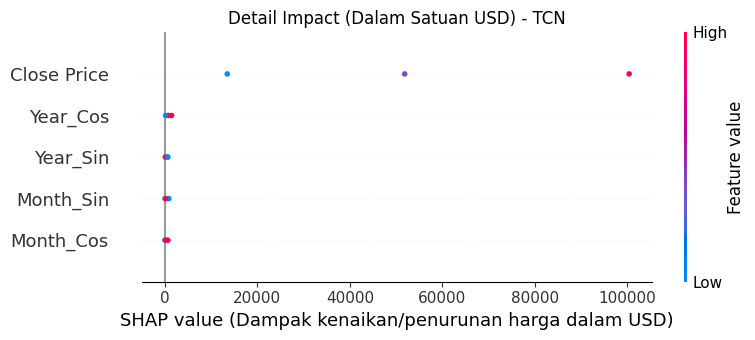

In [13]:
scale_factor = scaler.data_range_[0]
print(f"Faktor Skala Harga: {scale_factor} USD")
shap_values_usd = shap_values_aggr * scale_factor

plt.figure(figsize=(10, 6))
plt.title("Feature Importance (Dalam Satuan USD) - TCN")
shap.summary_plot(shap_values_usd, X_test_aggr, feature_names=feature_names, plot_type="bar", show=False)
plt.xlabel("Rata-rata dampak terhadap Harga Bitcoin (USD)")
plt.show()

plt.figure(figsize=(10, 6))
plt.title("Detail Impact (Dalam Satuan USD) - TCN")
shap.summary_plot(shap_values_usd, X_test_aggr, feature_names=feature_names, show=False)
plt.xlabel("SHAP value (Dampak kenaikan/penurunan harga dalam USD)")
plt.show()


## 8. Latent Space (t-SNE)

Setiap panel memakai run dengan RMSE test terendah. Pembacaannya bersifat kualitatif.


>>> Memulai Analisis Latent Space untuk: ['RNN', 'LSTM', 'TCN']
   > Ekstrak fitur & t-SNE untuk RNN...
   > Ekstrak fitur & t-SNE untuk LSTM...
   > Ekstrak fitur & t-SNE untuk TCN...


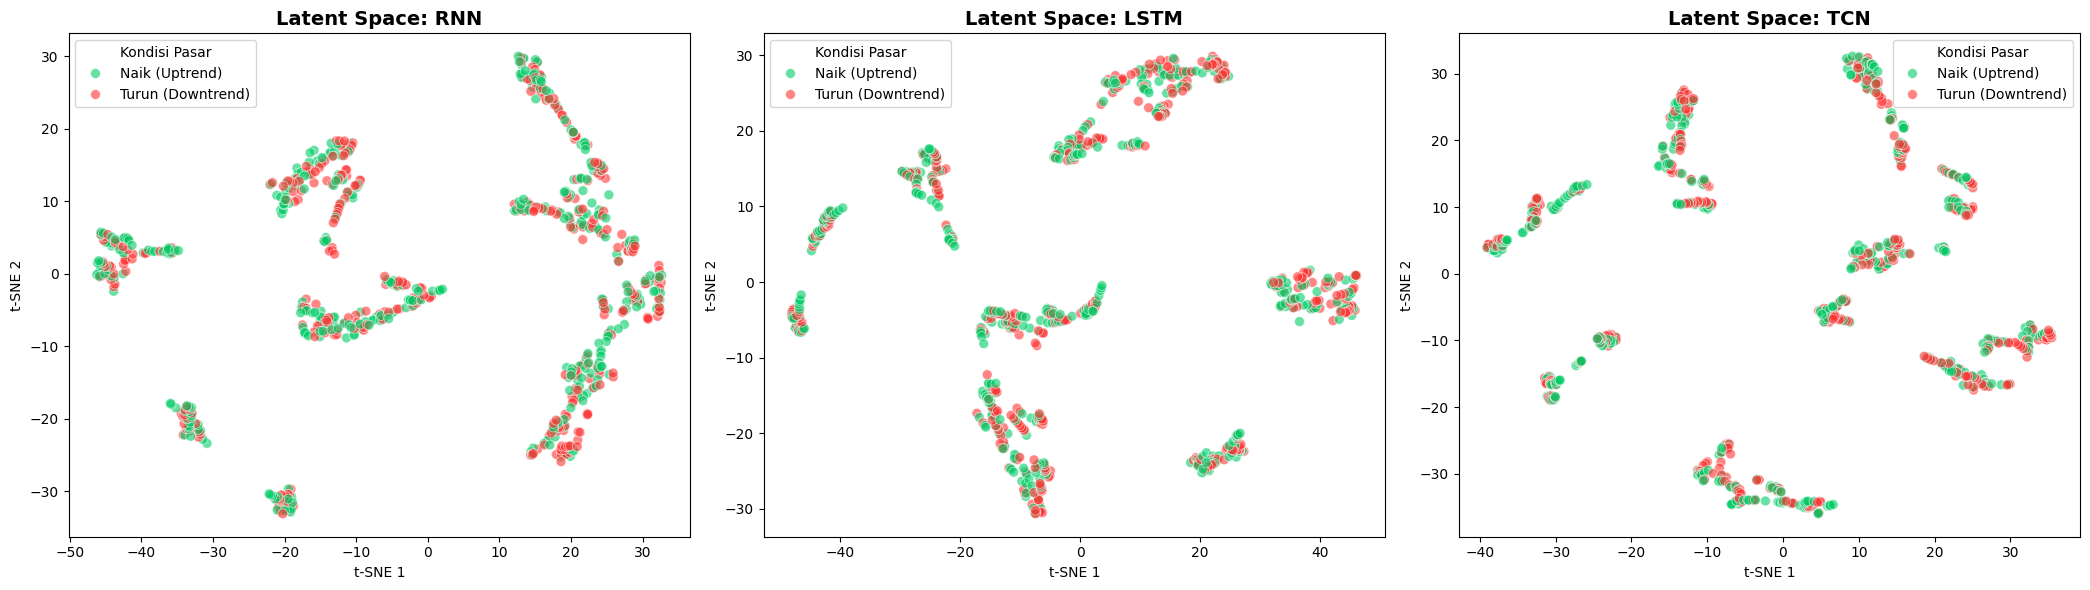

In [14]:
print(f">>> Memulai Analisis Latent Space untuk: {list(best_models.keys())}")

# Label tren: Close target dibandingkan Close hari sebelumnya
prev_prices_real = inverse_close(X_test[:, -1, 0])
labels = np.where(y_test_inv > prev_prices_real, 'Naik (Uptrend)', 'Turun (Downtrend)')

fig, axes = plt.subplots(1, len(best_models), figsize=(21, 6))

for ax, (name, model) in zip(axes, best_models.items()):
    print(f"   > Ekstrak fitur & t-SNE untuk {name}...")

    # Aktivasi Dense(16) sebelum output, direduksi 16 -> 2 dimensi
    extractor = tf.keras.Model(inputs=model.input, outputs=model.get_layer('latent_layer').output)
    latent_features = extractor.predict(X_test, verbose=0)
    tsne_results = TSNE(n_components=2, random_state=42, perplexity=30).fit_transform(latent_features)

    sns.scatterplot(
        x=tsne_results[:, 0], y=tsne_results[:, 1],
        hue=labels,
        palette={'Naik (Uptrend)': '#00cc66', 'Turun (Downtrend)': '#ff3333'},
        alpha=0.6, s=50,
        ax=ax,
    )
    ax.set_title(f"Latent Space: {name}", fontsize=14, fontweight='bold')
    ax.set_xlabel("t-SNE 1")
    ax.set_ylabel("t-SNE 2")
    ax.legend(title='Kondisi Pasar')

plt.tight_layout()
plt.show()


## 9. Aktivasi Layer TCN


Shape sample input: (1, 60, 5)
Visualisasi Aktivasi Layer: conv1d_7


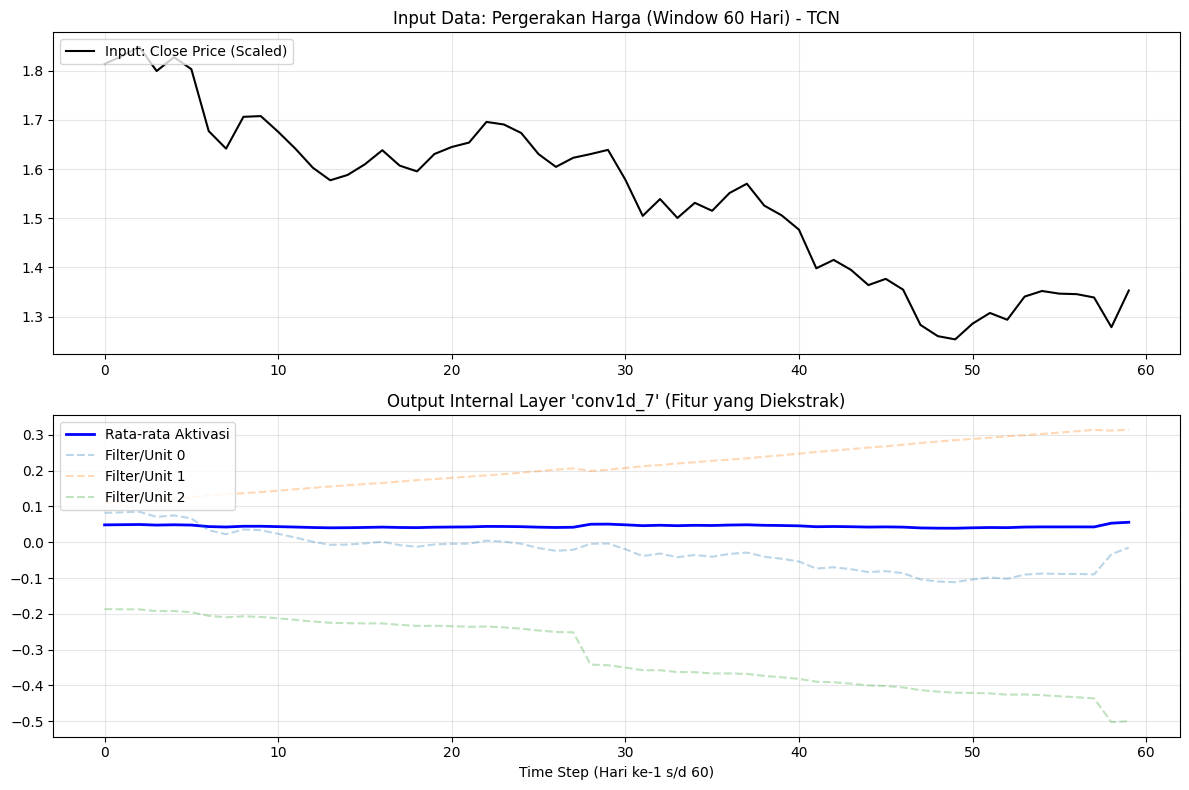

In [15]:
def visualize_activation(model, X_sample, model_name):
    # Ambil layer konvolusi pertama, yaitu fitur paling dasar
    target_layer = next(layer.name for layer in model.layers if 'conv1d' in layer.name.lower())
    print(f"Visualisasi Aktivasi Layer: {target_layer}")

    intermediate_model = tf.keras.Model(inputs=model.input, outputs=model.get_layer(target_layer).output)
    feature_maps = intermediate_model.predict(X_sample, verbose=0)

    plt.figure(figsize=(12, 8))

    plt.subplot(2, 1, 1)
    plt.plot(X_sample[0, :, 0], color='black', label='Input: Close Price (Scaled)')
    plt.title(f"Input Data: Pergerakan Harga (Window 60 Hari) - {model_name}")
    plt.grid(True, alpha=0.3)
    plt.legend(loc='upper left')

    plt.subplot(2, 1, 2)
    plt.plot(np.mean(feature_maps[0], axis=-1), color='blue', linewidth=2, label='Rata-rata Aktivasi')
    for i in range(min(3, feature_maps.shape[-1])):
        plt.plot(feature_maps[0, :, i], alpha=0.3, linestyle='--', label=f'Filter/Unit {i}')
    plt.title(f"Output Internal Layer '{target_layer}' (Fitur yang Diekstrak)")
    plt.xlabel("Time Step (Hari ke-1 s/d 60)")
    plt.grid(True, alpha=0.3)
    plt.legend(loc='upper left')

    plt.tight_layout()
    plt.show()


# Sampel terakhir pada data test
sample_input = X_test[-1:]
print(f"Shape sample input: {sample_input.shape}")
visualize_activation(best_models['TCN'], sample_input, 'TCN')
